# 02 · Stage 1 — OLS residual target & EDA
Composite risk = 0.7·Z(EB-smoothed MMR) + 0.3·Z(severe morbidity); OLS on institutional births; internally studentized residuals; four operational quadrants (blueprint §3.1).

In [1]:
import sys, pathlib, json, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.configuration import load_config, configured_path, feature_columns, zones
config = load_config()
P = lambda name: configured_path(config, name)
pd.set_option("display.max_columns", 40)

In [2]:
master = pd.read_csv(P("master_dataset"))
modelling = master.loc[master["priority_class"].notna()].copy()
modelling["priority_class"] = modelling["priority_class"].astype(int)
import joblib
stage1 = joblib.load(P("stage1_model"))
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in stage1.items() if k != "feature_columns"})
modelling["priority_label"].value_counts()

{'intercept': 0.3646, 'coefficient': -0.0041, 'residual_sigma': 0.7818, 'care_threshold': 92.4, 'risk_median': -0.1413, 'residual_threshold': 0.25}


priority_label
Best Performer          234
Coverage Gap            184
Low Burden              158
Priority / High-Risk    109
Name: count, dtype: int64

In [3]:
from src.target.ols_priority_classifier import FORBIDDEN_FEATURES, assert_no_leakage
assert_no_leakage(stage1["feature_columns"])
print("Anti-leakage firewall passed for", len(stage1["feature_columns"]), "features")

Anti-leakage firewall passed for 32 features


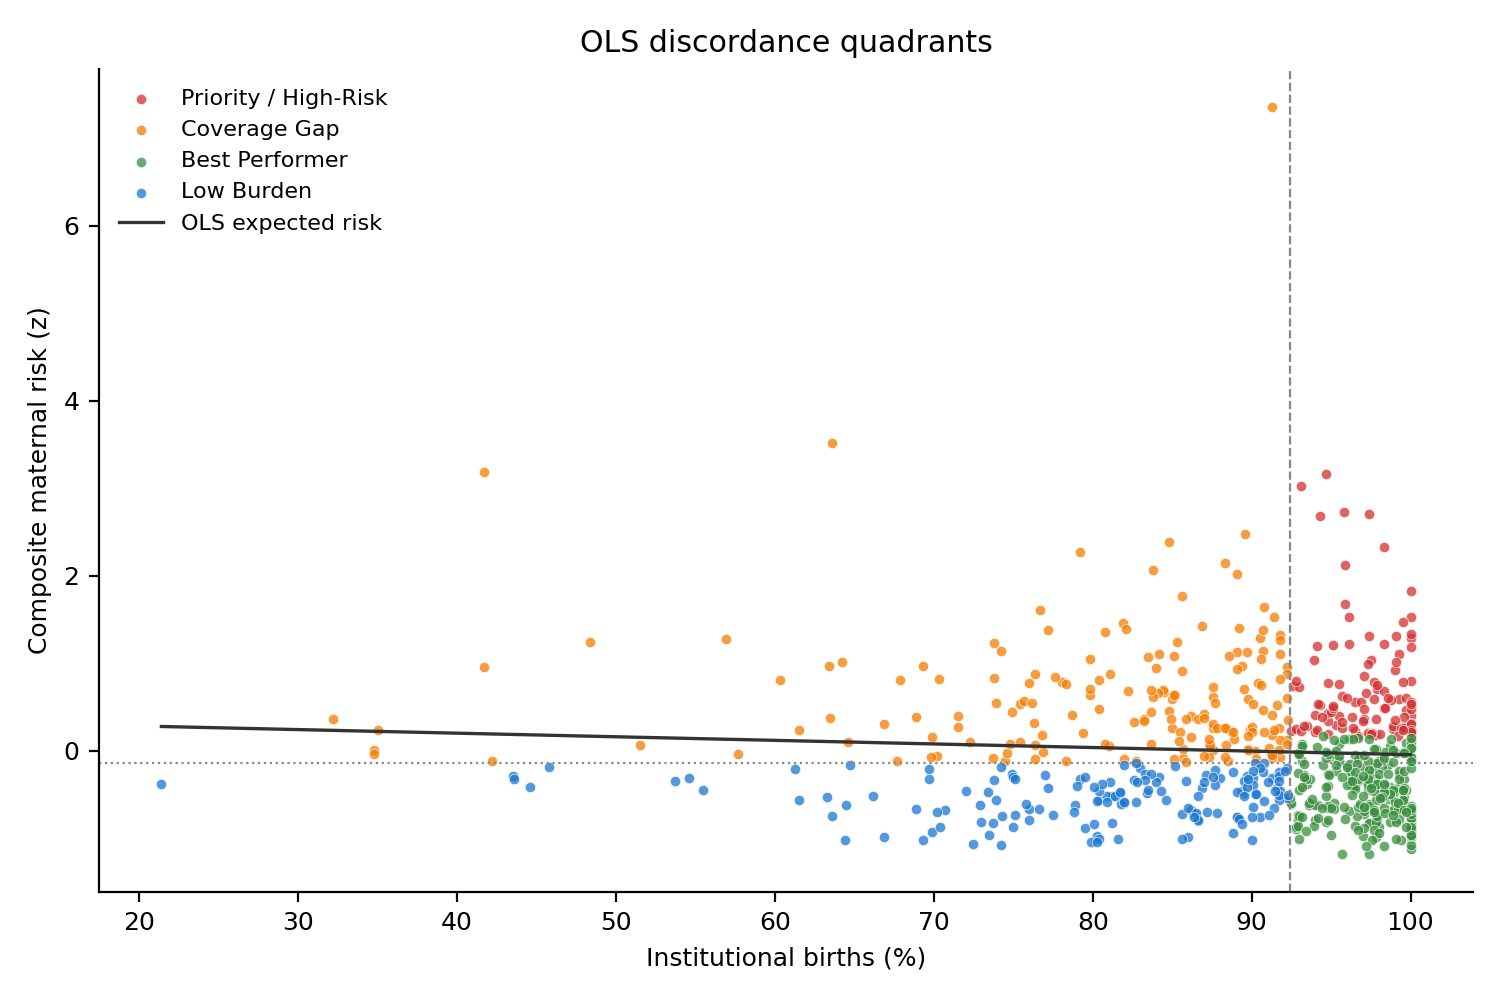

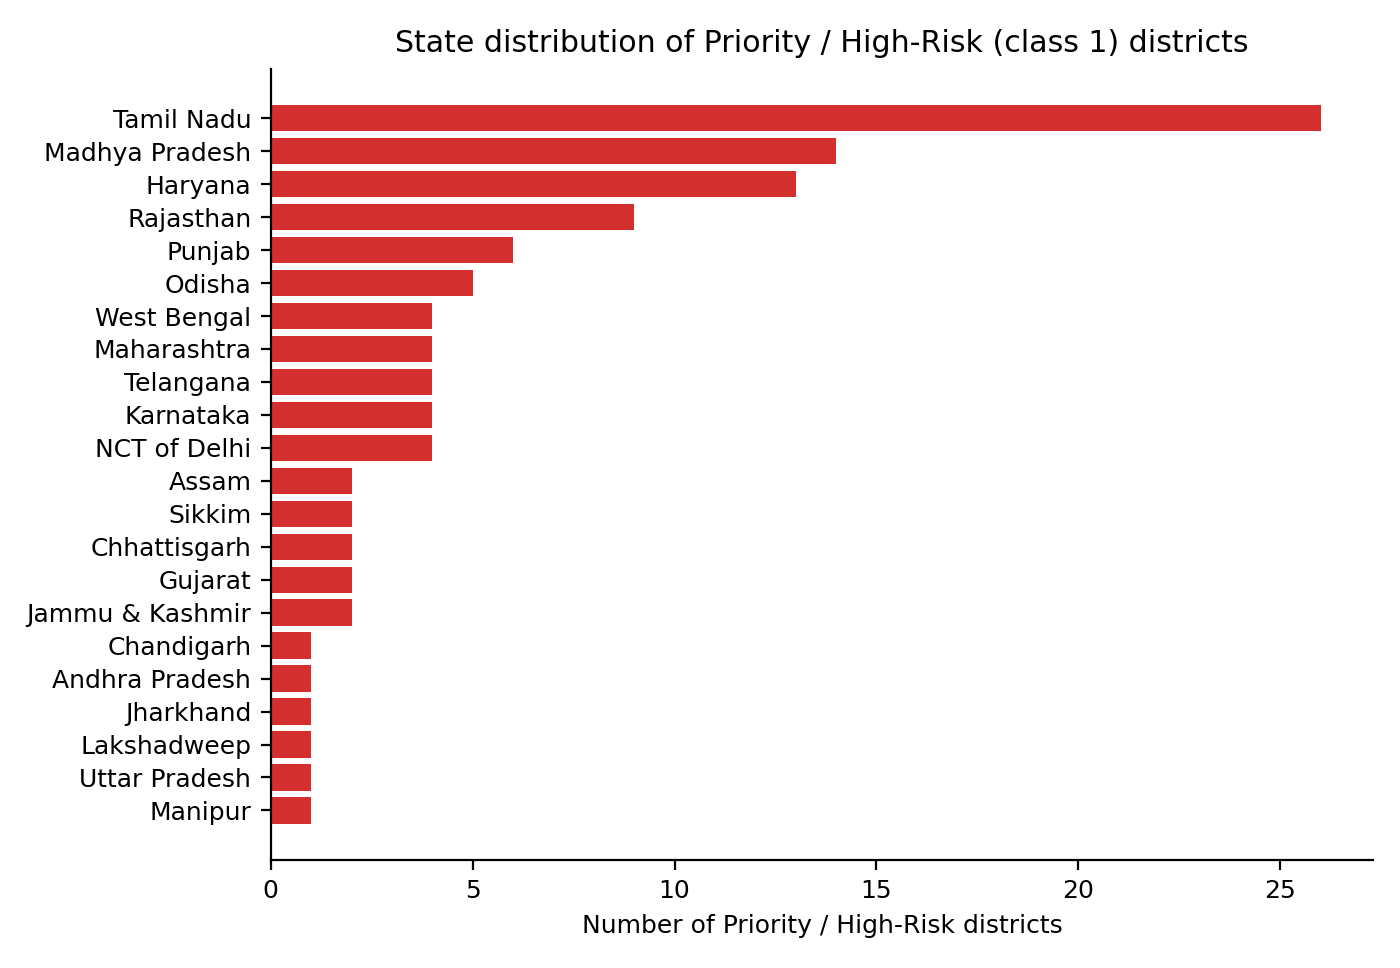

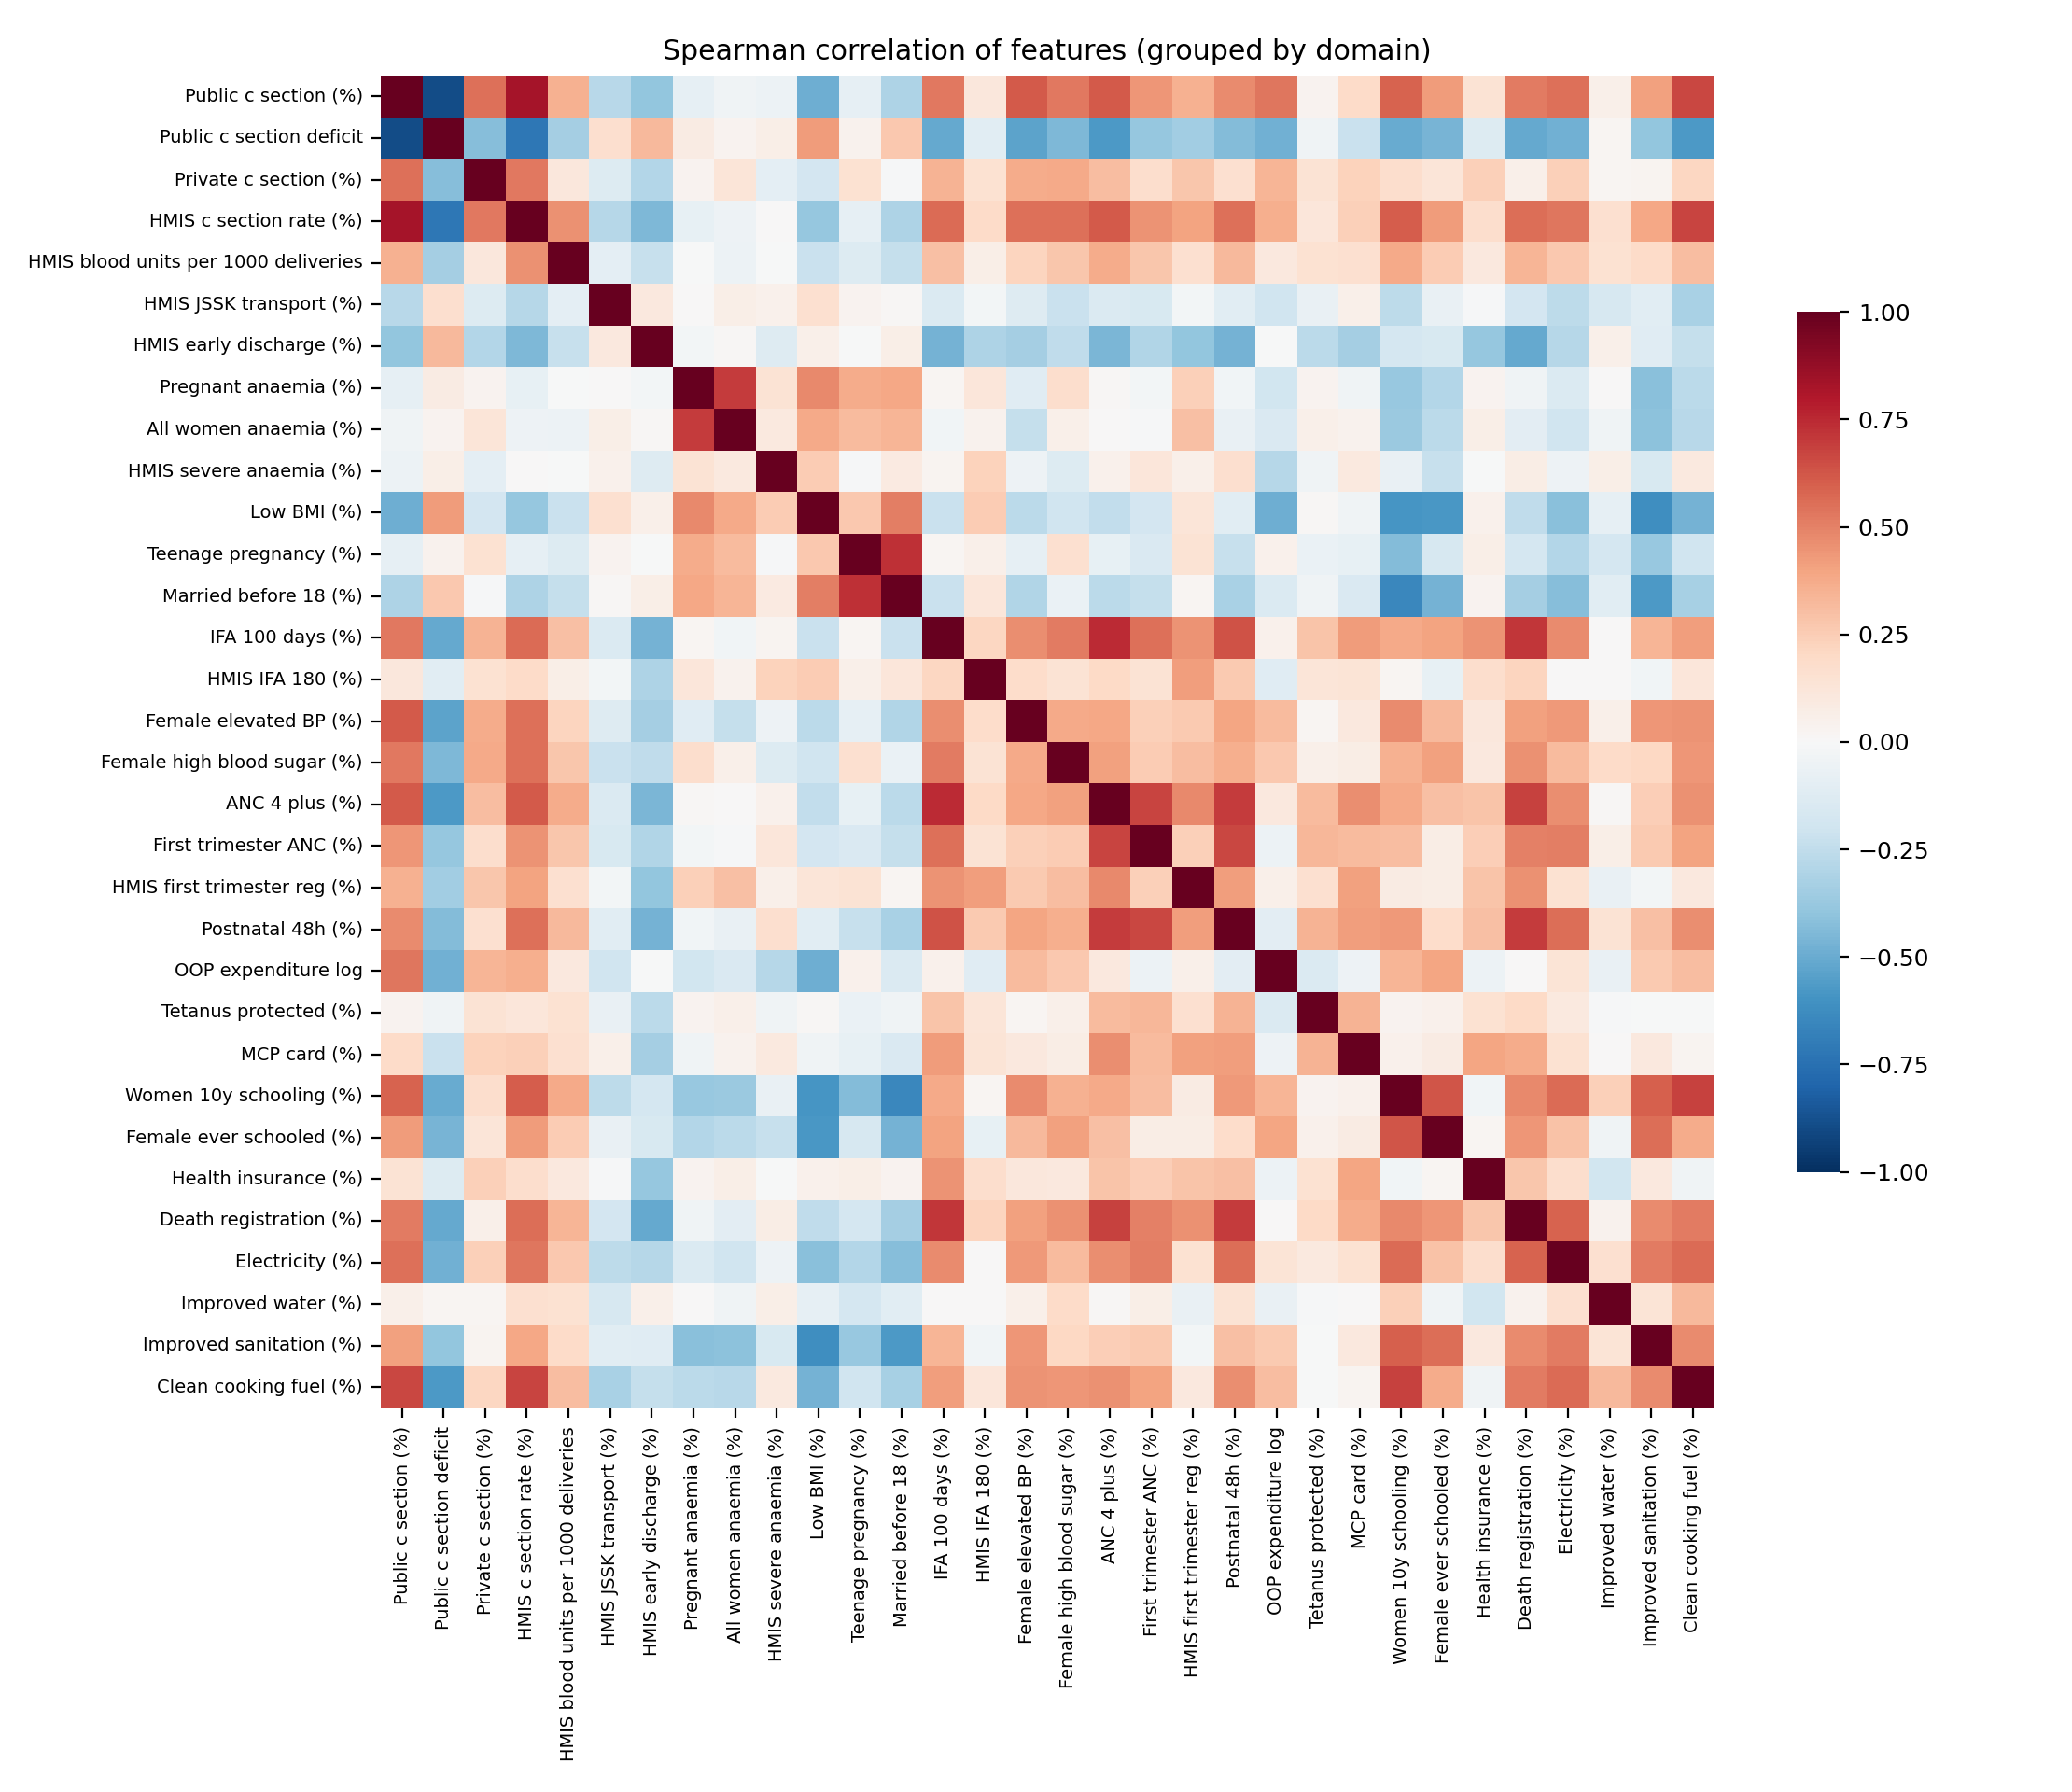

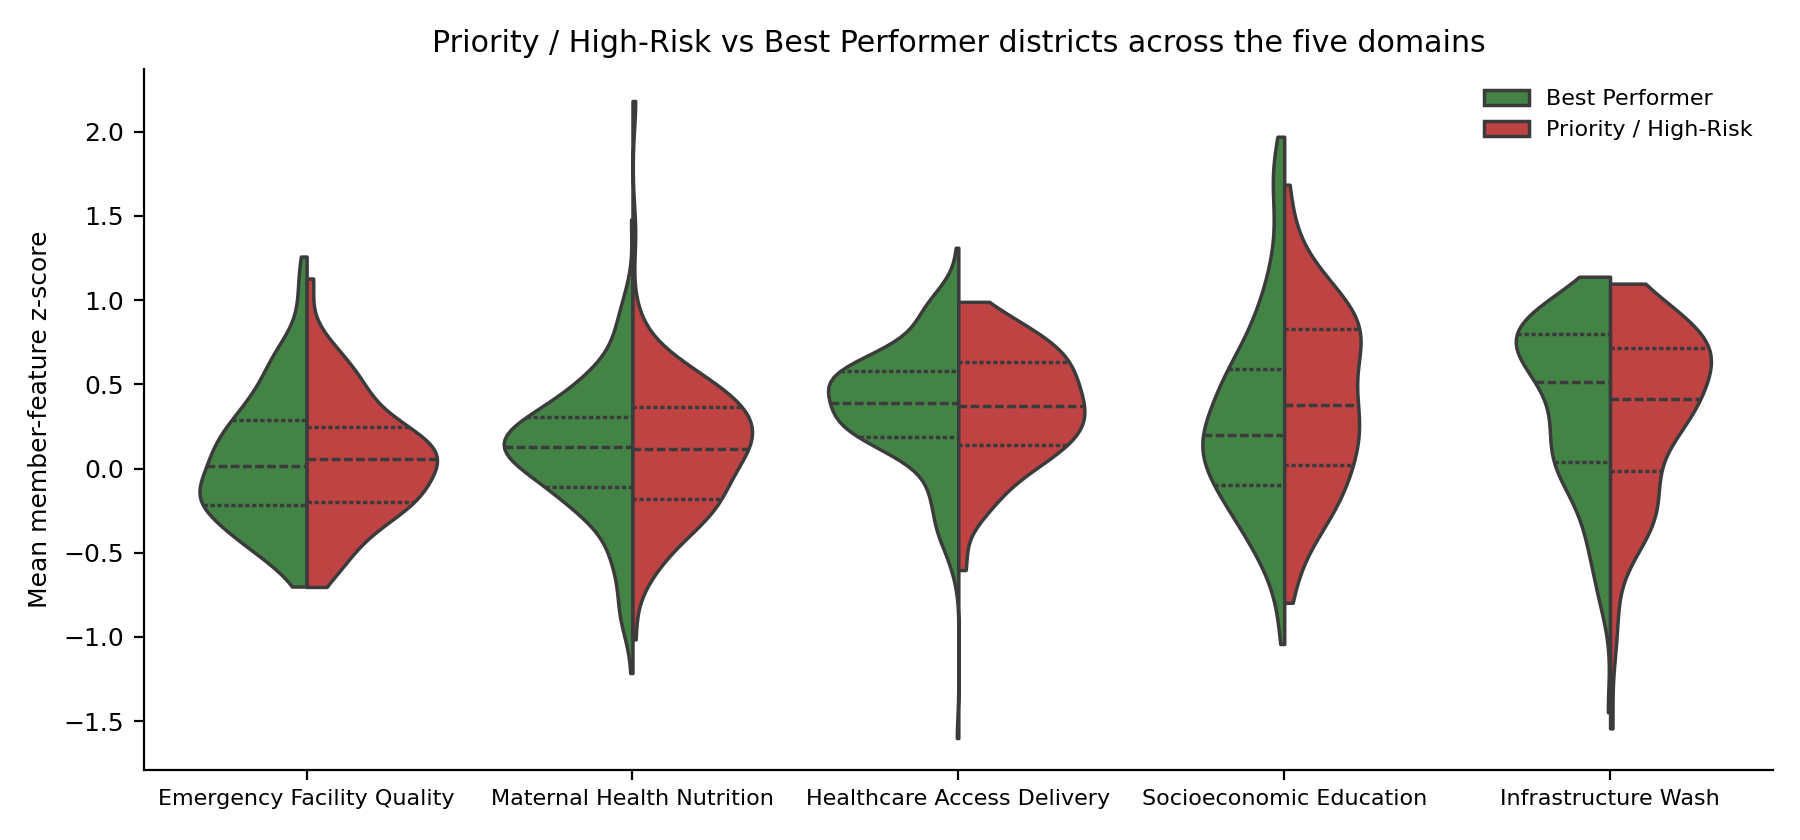

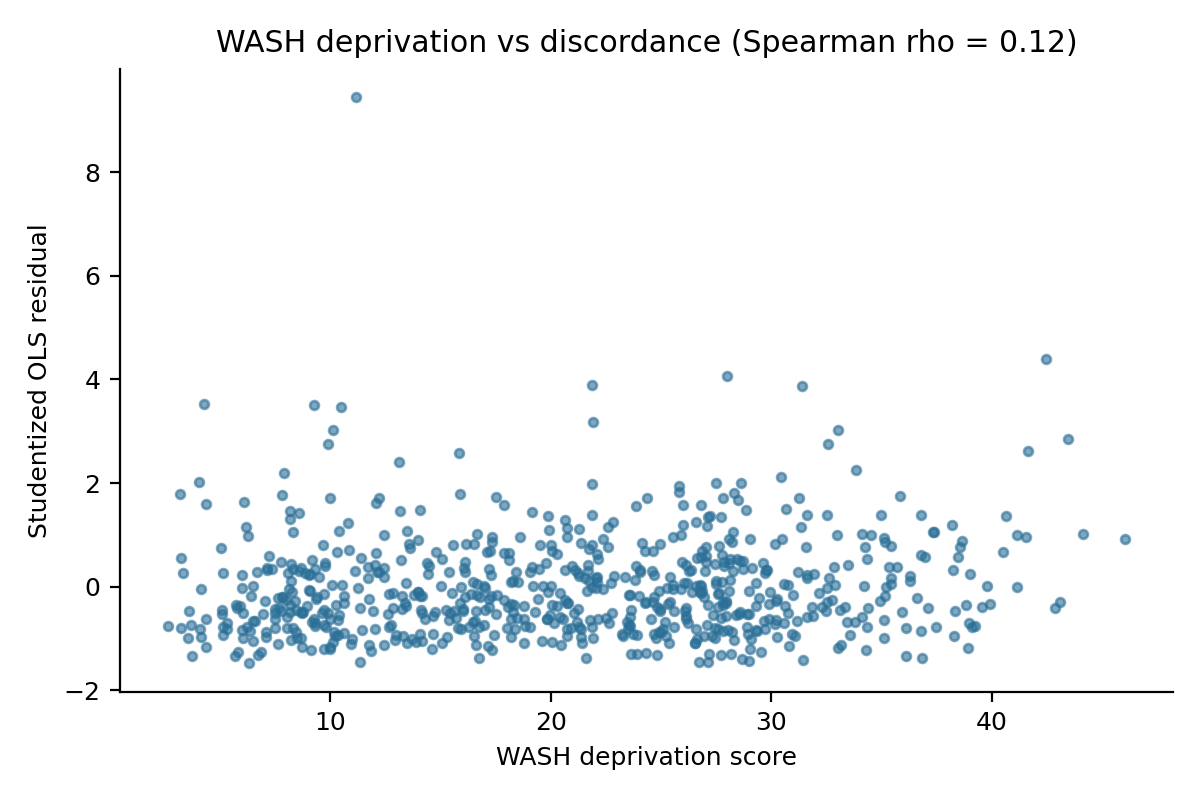

In [4]:
from src.reports.eda import generate_eda_figures
paths = generate_eda_figures(modelling, stage1["feature_columns"], stage1, P("figures"))
from IPython.display import Image, display
for path in paths:
    display(Image(filename=str(path), width=720))

In [5]:
modelling.groupby("state")["priority_class"].apply(lambda s: (s == 1).mean()).sort_values(ascending=False).head(10).to_frame("share of districts in class 1")

,share of districts in class 1
state,
Lakshadweep,1.000000
Chandigarh,1.000000
Tamil Nadu,0.812500
Sikkim,0.666667
Haryana,0.590909
NCT of Delhi,0.363636
Madhya Pradesh,0.274510
Rajasthan,0.272727
Punjab,0.272727
